# Q1.6 — Filament Cooling Simulation

Numerical simulation with a growing domain, finite differences, and explicit Euler integration.

**Usage:** Run cells from top to bottom (`Run All`). All quantities are in SI units. This notebook reorganizes the supplied Python script into notebook cells; the simulation logic is unchanged.

## 1. Parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ABS material properties
a = 0.0004         # m
rho = 1050.0       # kg/m^3
cp = 2020.0        # J/(kg K)
k = 0.20           # W/(m K)

# Heat transfer coefficients
he = 10.0          # W/(m^2 K)
hb = 100.0         # W/(m^2 K), assumed

# Temperatures
Te = 300.0         # K
Tb = 378.15        # K
Tdep = 513.15      # K

# Printing geometry
semi_xaxis = 0.08  # m
semi_yaxis = 0.05  # m
v = 0.02           # m/s

# Numerical parameters
ds_target = 0.002  # m
dt = 0.01          # s
epsilon = 0.5      # K

## 2. Printing Geometry

In [2]:
A = semi_xaxis
B = semi_yaxis

# Approximate perimeter of ellipse
L = np.pi * (3 * (A + B)- np.sqrt((3*A + B)*(A + 3*B)))
N = int(np.ceil(L / ds_target))
ds = L / N
t_print = L / v

# PDE coefficients
alpha = k / (rho * cp)
beta_e = 3 * he / (rho * cp * a)
beta_b = hb / (rho * cp * a)

# Stability check
stability = dt * (2 * alpha / ds**2 + beta_e + beta_b)
print("Path length:", L, "m")
print("Number of segments:", N)
print("Printing time:", t_print, "s")
print("Stability value:", stability)

Path length: 0.41386263611377977 m
Number of segments: 207
Printing time: 20.69313180568899 s
Stability value: 0.0020040848298287645


## 3. Heat Transfer Model

In [3]:
def temperature_rate(T, closed):
    conduction = np.zeros_like(T)
    if closed:
        # Closed loop: periodic boundaries
        conduction = alpha / ds**2 * (np.roll(T, 1) - 2*T + np.roll(T, -1))
    else:
        # Open filament
        if len(T) > 1:
            conduction[0] = alpha / ds**2 * (T[1] - T[0])
            conduction[-1] = alpha / ds**2 * (T[-2] - T[-1])
        if len(T) > 2:
            conduction[1:-1] = alpha / ds**2 * (T[:-2] - 2*T[1:-1] + T[2:])
    air = -beta_e * (T - Te)
    bed = -beta_b * (T - Tb)
    return conduction + air + bed

## 4. Numerical Simulation

In [4]:
# Initial conditions
T = np.array([Tdep], dtype=float)
t = 0.0
closed = False

# Record results
time_history = []
mean_temp_history = []
temp_range_history = []

# Phase 1: Printing
while t < t_print:
    # Update temperatures using Euler method
    step = min(dt, t_print - t)
    T = T + step * temperature_rate(T, closed)
    # Advance time
    t = t + step
    # Growing domain
    n_target = min(N, 1 + int(v * t / ds))
    if n_target > len(T):
        n_new = n_target - len(T)
        T = np.append(T, np.full(n_new, Tdep))
    # Save temperature information
    time_history.append(t)
    mean_temp_history.append(np.mean(T))
    temp_range_history.append(np.max(T) - np.min(T))

# Phase 2: Cooling
# Check that all N segments have been deposited
assert len(T) == N
# The filament is now a closed loop
# Save temperature distribution at printing completion
T_at_print = T.copy()
closed = True

# Maximum additional cooling duration
max_cooling_time = 1000.0
cooling_start = t
while t - cooling_start < max_cooling_time:
    temperature_difference = np.max(T) - np.min(T)
    if temperature_difference <= epsilon:
        break
    T = T + dt * temperature_rate(T, closed)
    t = t + dt
    time_history.append(t)
    mean_temp_history.append(np.mean(T))
    temp_range_history.append(np.max(T) - np.min(T))

# Simulation Results
t_total = t
t_cooling = t_total - t_print
print("Printing time:", t_print, "s")
print("Total simulation time:", t_total, "s")
print("Cooling time:", t_cooling, "s")
print("Final temperature difference:", np.max(T) - np.min(T), "K")

Printing time: 20.69313180568899 s
Total simulation time: 57.27313180568573 s
Cooling time: 36.579999999996744 s
Final temperature difference: 0.49937875079865535 K


## 5. Results and Plots

The plots render directly below their respective notebook cells.

### 5.1 Mean Filament Temperature over Time

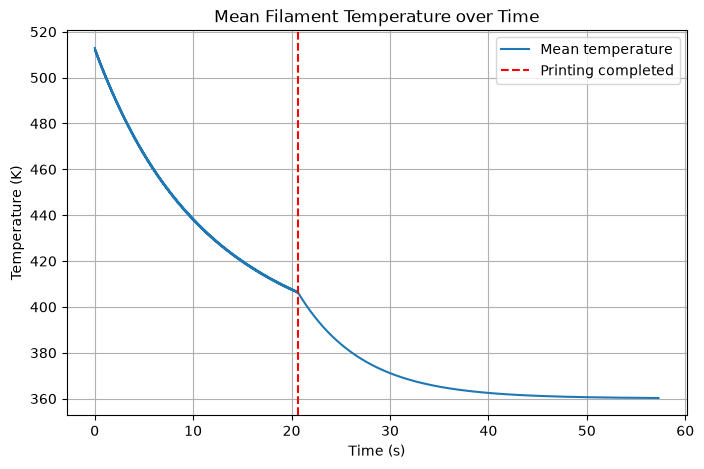

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(time_history, mean_temp_history,label="Mean temperature")
plt.axvline(t_print, color="red",linestyle="--", label="Printing completed")
plt.xlabel("Time (s)")
plt.ylabel("Temperature (K)")
plt.title("Mean Filament Temperature over Time")
plt.legend()
plt.grid(True)
plt.show()

### 5.2 Temperature Difference over Time

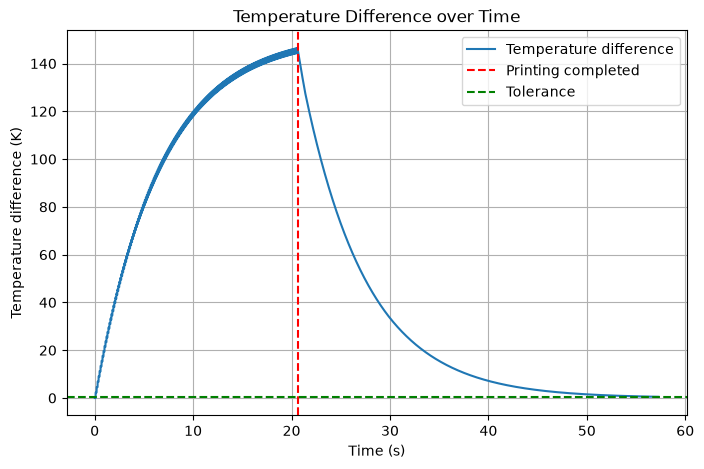

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(time_history, temp_range_history,label="Temperature difference")
plt.axvline(t_print, color="red",linestyle="--", label="Printing completed")
plt.axhline(epsilon, color="green",linestyle="--", label="Tolerance")
plt.xlabel("Time (s)")
plt.ylabel("Temperature difference (K)")
plt.title("Temperature Difference over Time")
plt.legend()
plt.grid(True)
plt.show()

### 5.3 Temperature Distribution Along the Filament

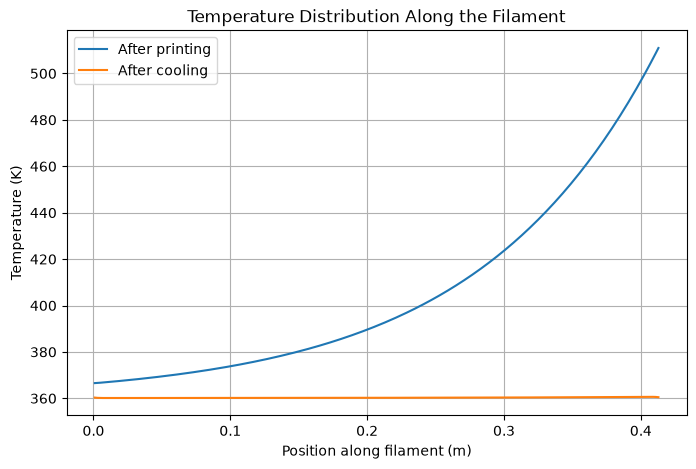

In [7]:
s = (np.arange(N) + 0.5) * ds
plt.figure(figsize=(8, 5))
plt.plot(s, T_at_print,label="After printing")
plt.plot(s, T,label="After cooling")
plt.xlabel("Position along filament (m)")
plt.ylabel("Temperature (K)")
plt.title("Temperature Distribution Along the Filament")
plt.legend()
plt.grid(True)
plt.show()